# T08 · Decision Tree & Random Forest (Gini/Entropy/Gain · Tree construction · Rules · Overfitting · Parameters · RF)

**ใช้เมื่อโจทย์ถาม:** คำนวณ Gini / Entropy / Information Gain / Gain Ratio เลือก root · สร้างต้นไม้ + วาด + เขียนกฎ IF-THEN ·
feature importance · overfitting (train vs test, ปรับ max_depth / min_samples_leaf) · criterion gini vs entropy ·
Random Forest (n_estimators, max_features) · tune + เทียบ DT vs RF vs baseline · ทำนายข้อมูลใหม่ + อธิบายเส้นทาง

| ขั้น | ทำอะไร |
|---|---|
| 1 | แก้ **⚙️ CONFIG** · Run All |
| 2 | §0 = คำนวณ impurity ด้วยมือ (ข้อมูลเล็ก เช่น weather) — config แยกในเซลล์ |

> Tree/RF **ไม่ต้อง scale** (แบ่งตาม threshold ไม่ใช่ระยะทาง) · RapidMiner Decision Tree default = **gain_ratio** + pruning · sklearn = **gini** ไม่ prune

In [1]:
# ════════ ⚙️ CONFIG — แก้ cell นี้ให้ตรงโจทย์ ════════
DATA_PATH = "../practice/data/p6_heart.csv"
TARGET    = "target"
POS_LABEL = 1
ID_COL    = None
DROP_COLS = []
CRITERION = "gini"          # "gini" | "entropy" (= information gain)
MAX_DEPTH = 3               # ความลึกที่โจทย์กำหนด (None = โตจนสุด)
MIN_LEAF  = 1               # min_samples_leaf
N_TREES   = 100             # Random Forest n_estimators
NEW_DATA  = None            # dict ข้อมูลใหม่ / path .csv · None = ใช้แถวแรกของ test เป็นตัวอย่าง
EVAL_MODE = "cv"
SCALE     = None            # tree ไม่ต้อง scale
TEST_SIZE, N_FOLDS, SEED = 0.2, 5, 42
MISSING_MARKERS, SHEET, CSV_SEP = ["?", "", " ", "NA"], 0, ","

In [2]:
# ════════ 🔧 IMPORTS + HELPERS — ไม่ต้องแก้ cell นี้ แค่รันหลัง CONFIG ════════
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder,
                                   KBinsDiscretizer, LabelEncoder)
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, NearestNeighbors
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import (DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text)
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score, silhouette_samples, davies_bouldin_score)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# ค่า default ถ้า CONFIG ไม่ได้กำหนดไว้ (กันลืม)
for _name, _val in {"SEED": 42, "N_FOLDS": 5, "TEST_SIZE": 0.2, "TARGET": None, "POS_LABEL": None,
                    "ID_COL": None, "DROP_COLS": [], "MISSING_MARKERS": ["?", "", " ", "NA", "N/A", "null"],
                    "SHEET": 0, "CSV_SEP": ",", "SCALE": "standard"}.items():
    globals().setdefault(_name, _val)


def load_data(path, sheet=None, sep=None, na_values=None):
    """อ่าน .csv / .xlsx / .xls → ตัดช่องว่างหัวคอลัมน์และค่า string → แปลงค่าแฝง ('?', '') เป็น NaN"""
    sheet = SHEET if sheet is None else sheet
    sep = CSV_SEP if sep is None else sep
    na_values = MISSING_MARKERS if na_values is None else na_values
    if str(path).lower().endswith((".xlsx", ".xls")):
        df = pd.read_excel(path, sheet_name=sheet)
    else:
        df = pd.read_csv(path, sep=sep)
    df.columns = [str(c).strip() for c in df.columns]
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            df[c] = df[c].map(lambda v: v.strip() if isinstance(v, str) else v)
    df = df.replace(list(na_values), np.nan)
    # คอลัมน์ที่เป็นตัวเลขแต่ถูกอ่านเป็น text (เพราะเคยมี '?') → แปลงกลับเป็นตัวเลข
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            conv = pd.to_numeric(df[c], errors="coerce")
            if conv.notna().sum() == df[c].notna().sum() and df[c].notna().any():
                df[c] = conv
    print(f"โหลด {path} → {df.shape[0]} แถว × {df.shape[1]} คอลัมน์")
    return df


def check(df, target=None):
    """ตรวจข้อมูลใน 1 คำสั่ง: ขนาด · ชนิด · ค่าว่าง · unique · ตัวอย่างค่า · สัดส่วน target"""
    print("shape:", df.shape, "| แถวซ้ำ:", int(df.duplicated().sum()))
    info = pd.DataFrame({"dtype": df.dtypes.astype(str),
                         "missing": df.isna().sum(),
                         "missing_%": (df.isna().mean() * 100).round(2),
                         "unique": df.nunique(),
                         "example": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df]})
    display(info)
    if target is not None and target in df and pd.api.types.is_numeric_dtype(df[target]) and df[target].nunique() > 15:
        print(f"target '{target}' เป็นตัวเลข (regression):")
        display(df[target].describe().to_frame().T)
    elif target is not None and target in df:
        vc = pd.concat([df[target].value_counts(dropna=False), df[target].value_counts(normalize=True, dropna=False).round(4)],
                       axis=1, keys=["count", "ratio"])
        print(f"การกระจายของ target '{target}':")
        display(vc)


def num_cols(df):
    return df.select_dtypes(include="number").columns.tolist()


def cat_cols(df):
    return [c for c in df.columns if c not in num_cols(df)]


def make_xy(df, target=None, drop=None, pos_label=None, task="classification"):
    """แยก X / y · ตัด target + DROP_COLS + ID_COL · classification 2 คลาส → y = 1 ถ้าเท่ากับ POS_LABEL"""
    target = TARGET if target is None else target
    drop = DROP_COLS if drop is None else drop
    pos_label = POS_LABEL if pos_label is None else pos_label
    d = df.dropna(subset=[target]).copy()
    removed = [c for c in list(drop) + [ID_COL] if c is not None and c in d.columns and c != target]
    X = d.drop(columns=[target] + removed)
    if task == "regression":
        y = d[target].astype(float)
        print(f"X: {X.shape} | y = '{target}' (ตัวเลข) | ตัดคอลัมน์: {removed}")
        return X, y
    raw = d[target]
    classes = sorted(raw.astype(str).unique())
    if len(classes) == 2:
        pos = str(pos_label) if pos_label is not None else classes[-1]
        if pos not in classes:
            raise ValueError(f"POS_LABEL={pos_label!r} ไม่อยู่ใน {classes} — แก้ใน CONFIG")
        neg = [c for c in classes if c != pos][0]
        y = (raw.astype(str) == pos).astype(int).rename(target)
        print(f"X: {X.shape} | y = '{target}' → 1 = {pos!r} (positive), 0 = {neg!r} | ตัดคอลัมน์: {removed}")
    else:
        y = raw.astype(str)
        print(f"X: {X.shape} | y = '{target}' มี {len(classes)} คลาส {classes} (multiclass → ใช้ macro avg) | ตัดคอลัมน์: {removed}")
    return X, y


def is_binary(y):
    return pd.Series(y).nunique() == 2


def build_prep(X, scale="config", num_impute="median", onehot=True):
    """preprocessing ที่ fit เฉพาะ train (ใส่ใน Pipeline → ไม่ leak)
    ตัวเลข: เติมค่าว่าง (median) → scale ('standard' z-score | 'minmax' 0–1 | None)
    หมวดหมู่: เติมค่าว่าง (ค่าที่พบบ่อยสุด) → one-hot"""
    if scale == "config":                      # ไม่ระบุ → ใช้ SCALE จาก CONFIG · ส่ง None = ไม่ scale
        scale = SCALE
    nums, cats = num_cols(X), cat_cols(X)
    scaler = {"standard": StandardScaler(), "minmax": MinMaxScaler()}.get(scale, "passthrough")
    num_pipe = Pipeline([("impute", SimpleImputer(strategy=num_impute)), ("scale", scaler)])
    enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False) if onehot else \
        OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("encode", enc)])
    return ColumnTransformer([("num", num_pipe, nums), ("cat", cat_pipe, cats)],
                             verbose_feature_names_out=False)


def make_pipe(model, X, scale="config", **kw):
    """Pipeline = preprocessing (fit บน train fold เท่านั้น) + model"""
    return Pipeline([("prep", build_prep(X, scale=scale, **kw)), ("model", model)])


def get_cv(task="classification", n=None):
    n = N_FOLDS if n is None else n
    if task == "regression":
        return KFold(n_splits=n, shuffle=True, random_state=SEED)
    return StratifiedKFold(n_splits=n, shuffle=True, random_state=SEED)


def cls_scoring(y):
    if is_binary(y):
        return {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1"}
    return {"accuracy": "accuracy", "precision": "precision_macro", "recall": "recall_macro", "f1": "f1_macro"}


def evaluate(name, model, X, y, cv=None, settings="", train=False):
    """classification ด้วย cross-validation → 1 แถว (ค่าเฉลี่ยทุก fold) ใช้ต่อเป็นตารางเปรียบเทียบ"""
    cv = get_cv() if cv is None else cv
    r = cross_validate(model, X, y, cv=cv, scoring=cls_scoring(y), return_train_score=train)
    row = {"model": name, "settings": settings}
    row.update({m: r[f"test_{m}"].mean() for m in ["accuracy", "precision", "recall", "f1"]})
    row["f1_std"] = r["test_f1"].std()
    if train:
        row["train_accuracy"] = r["train_accuracy"].mean()
    return row


def evaluate_holdout(name, model, X_tr, y_tr, X_te, y_te, settings=""):
    """classification แบบ hold-out: fit บน train → วัดบน test"""
    model.fit(X_tr, y_tr)
    p = model.predict(X_te)
    avg = "binary" if is_binary(y_tr) else "macro"
    return {"model": name, "settings": settings,
            "accuracy": accuracy_score(y_te, p),
            "precision": precision_score(y_te, p, average=avg, zero_division=0),
            "recall": recall_score(y_te, p, average=avg, zero_division=0),
            "f1": f1_score(y_te, p, average=avg, zero_division=0),
            "train_accuracy": accuracy_score(y_tr, model.predict(X_tr))}


def reg_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": float(mean_absolute_error(y_true, y_pred)), "MSE": float(mse), "RMSE": float(np.sqrt(mse)),
            "R2": float(r2_score(y_true, y_pred))}


def evaluate_reg(name, model, X, y, cv=None, settings=""):
    """regression ด้วย cross-validation → MAE / MSE / RMSE / R²"""
    cv = get_cv("regression") if cv is None else cv
    r = cross_validate(model, X, y, cv=cv,
                       scoring=["neg_mean_absolute_error", "neg_mean_squared_error", "r2"])
    mse = -r["test_neg_mean_squared_error"].mean()
    return {"model": name, "settings": settings, "MAE": -r["test_neg_mean_absolute_error"].mean(),
            "MSE": mse, "RMSE": np.sqrt(mse), "R2": r["test_r2"].mean()}


def show_cm(y_true, y_pred, title="Confusion matrix"):
    """confusion matrix (แถว = actual, คอลัมน์ = predicted) + classification report"""
    labels = sorted(pd.Series(y_true).unique(), key=str)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    display(pd.DataFrame(cm, index=[f"actual {l}" for l in labels], columns=[f"pred {l}" for l in labels]))
    if len(labels) == 2:
        tn, fp, fn, tp = cm.ravel()
        print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
    print(classification_report(y_true, y_pred, digits=4, zero_division=0))
    fig, ax = plt.subplots(figsize=(4, 3.4))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title); ax.grid(False); plt.show()


def top_k(grid, n=10):
    """ตารางผล GridSearchCV เรียงจากดีสุด"""
    res = pd.DataFrame(grid.cv_results_)
    cols = [c for c in res if c.startswith("param_")] + \
           [c for c in res if c.startswith("mean_test_") or c.startswith("mean_train_")]
    key = f"mean_test_{grid.refit}" if isinstance(grid.refit, str) else "mean_test_score"
    return res[cols].sort_values(key, ascending=False).head(n).reset_index(drop=True)


def results_table(rows, sort_by=None, ascending=False):
    t = pd.DataFrame(rows)
    if sort_by:
        t = t.sort_values(sort_by, ascending=ascending)
    display(t.reset_index(drop=True))
    return t.reset_index(drop=True)


def say_compare(table, metric="f1", baseline_name=None, higher_is_better=True):
    """พิมพ์ประโยคตีความสำเร็จรูปจากตารางผล (copy ไปใส่คำตอบได้เลย)"""
    t = table.sort_values(metric, ascending=not higher_is_better)
    best = t.iloc[0]
    msg = f"✍️ โมเดลที่ดีที่สุดตาม {metric} คือ {best['model']}"
    if str(best.get("settings", "")):
        msg += f" ({best['settings']})"
    msg += f" ได้ {metric} = {best[metric]:.4f}"
    if baseline_name is not None and baseline_name in set(table["model"]):
        b = table.loc[table["model"] == baseline_name].iloc[0]
        diff = best[metric] - b[metric]
        msg += f" เทียบกับ baseline ({baseline_name}) ที่ได้ {b[metric]:.4f} ต่างกัน {diff:+.4f}"
        if "accuracy" in table and metric != "accuracy":
            msg += f" (baseline accuracy = {b['accuracy']:.4f} แต่ {metric} ต่ำ → accuracy อย่างเดียวหลอกได้ถ้าคลาสไม่สมดุล)"
    print(msg)


def new_data(source):
    """ข้อมูลใหม่ที่จะทำนาย: path ไฟล์ (str) / dict 1 แถว / list ของ dict / DataFrame"""
    if source is None:
        return None
    if isinstance(source, str):
        return load_data(source)
    if isinstance(source, dict):
        return pd.DataFrame([source])
    if isinstance(source, list):
        return pd.DataFrame(source)
    return source.copy()


def align_new(df_new, X_ref):
    """จัดคอลัมน์ข้อมูลใหม่ให้ตรงกับ X ที่ใช้ train (คอลัมน์ที่ขาดเติม NaN → imputer จัดการ)"""
    missing = [c for c in X_ref.columns if c not in df_new.columns]
    if missing:
        print("⚠️ ข้อมูลใหม่ขาดคอลัมน์:", missing, "→ เติม NaN (imputer จะเติมให้)")
    return df_new.reindex(columns=X_ref.columns)

print("✅ helpers พร้อม | SEED =", SEED, "| N_FOLDS =", N_FOLDS)

✅ helpers พร้อม | SEED = 42 | N_FOLDS = 5


## §0 คำนวณ impurity ด้วยมือ — เลือก attribute ที่ดีที่สุดเป็น root
- $Entropy = -\sum p_j \log_2 p_j$ · $Gini = 1-\sum p_j^2$
- **Information Gain** = Entropy(parent) − Σ (n_k/n)·Entropy(child_k)
- **Gain Ratio** = Gain / SplitInfo, $SplitInfo = -\sum \frac{n_k}{n}\log_2\frac{n_k}{n}$ (ลงโทษ attribute ที่มีหลายค่า)
- **Gini gain** = Gini(parent) − Σ (n_k/n)·Gini(child_k)
- attribute ตัวเลข → ลองทุกจุดตัด (ค่ากึ่งกลาง) แบบ binary `≤ t / > t`

In [3]:
IMP_PATH   = "../data/weather.csv"      # ✏️ ข้อมูลเล็กที่โจทย์ให้คำนวณมือ (ใช้ DATA_PATH ก็ได้)
IMP_TARGET = "Class"                    # ✏️
IMP_DROP   = []                         # ✏️ เช่น ["Tid"]

def entropy(s):
    p = s.value_counts(normalize=True); return float(-(p * np.log2(p)).sum())
def gini(s):
    p = s.value_counts(normalize=True); return float(1 - (p ** 2).sum())

def split_scores(d, attr, target):
    n = len(d); parts = []
    if pd.api.types.is_numeric_dtype(d[attr]) and d[attr].nunique() > 4:
        vals = np.sort(d[attr].unique()); best = None
        for t in (vals[:-1] + vals[1:]) / 2:
            g = d[target].groupby(d[attr] <= t)
            w_gini = sum(len(s) / n * gini(s) for _, s in g)
            if best is None or w_gini < best[1]:
                best = (t, w_gini)
        t = best[0]; groups = {f"<= {t:g}": d[d[attr] <= t][target], f"> {t:g}": d[d[attr] > t][target]}
    else:
        groups = {str(k): s for k, s in d.groupby(attr)[target]}
    w_ent = sum(len(s) / n * entropy(s) for s in groups.values())
    w_gini = sum(len(s) / n * gini(s) for s in groups.values())
    split_info = -sum(len(s) / n * np.log2(len(s) / n) for s in groups.values())
    gain = entropy(d[target]) - w_ent
    detail = "; ".join(f"{k}: {dict(s.value_counts())} E={entropy(s):.3f} G={gini(s):.3f}" for k, s in groups.items())
    return {"attribute": attr, "weighted_entropy": w_ent, "info_gain": gain, "split_info": split_info,
            "gain_ratio": gain / split_info if split_info > 0 else 0, "weighted_gini": w_gini,
            "gini_gain": gini(d[target]) - w_gini, "children": detail}

imp = load_data(IMP_PATH).drop(columns=IMP_DROP, errors="ignore")
print(f"parent: {dict(imp[IMP_TARGET].value_counts())} → Entropy = {entropy(imp[IMP_TARGET]):.4f} · Gini = {gini(imp[IMP_TARGET]):.4f}")
imp_tab = pd.DataFrame([split_scores(imp, a, IMP_TARGET) for a in imp.columns if a != IMP_TARGET])
display(imp_tab.drop(columns="children").sort_values("info_gain", ascending=False))
for _, r in imp_tab.iterrows():
    print(f"  {r['attribute']}: {r['children']}")
print(f"✍️ root ตาม Information Gain = {imp_tab.loc[imp_tab.info_gain.idxmax(), 'attribute']} · "
      f"ตาม Gain Ratio = {imp_tab.loc[imp_tab.gain_ratio.idxmax(), 'attribute']} · ตาม Gini = {imp_tab.loc[imp_tab.gini_gain.idxmax(), 'attribute']}")

โหลด ../data/weather.csv → 14 แถว × 5 คอลัมน์
parent: {'P': np.int64(9), 'N': np.int64(5)} → Entropy = 0.9403 · Gini = 0.4592


,attribute,weighted_entropy,info_gain,split_info,gain_ratio,weighted_gini,gini_gain
0,Outlook,0.6935,0.2467,1.5774,0.1564,0.3429,0.1163
2,Humidity,0.7885,0.1518,1.0000,0.1518,0.3673,0.0918
3,Windy,0.8922,0.0481,0.9852,0.0488,0.4286,0.0306
1,Temperature,0.9111,0.0292,1.5567,0.0188,0.4405,0.0187


  Outlook: overcast: {'P': np.int64(4)} E=-0.000 G=0.000; rain: {'P': np.int64(3), 'N': np.int64(2)} E=0.971 G=0.480; sunny: {'N': np.int64(3), 'P': np.int64(2)} E=0.971 G=0.480
  Temperature: cool: {'P': np.int64(3), 'N': np.int64(1)} E=0.811 G=0.375; hot: {'N': np.int64(2), 'P': np.int64(2)} E=1.000 G=0.500; mild: {'P': np.int64(4), 'N': np.int64(2)} E=0.918 G=0.444
  Humidity: high: {'N': np.int64(4), 'P': np.int64(3)} E=0.985 G=0.490; normal: {'P': np.int64(6), 'N': np.int64(1)} E=0.592 G=0.245
  Windy: False: {'P': np.int64(6), 'N': np.int64(2)} E=0.811 G=0.375; True: {'N': np.int64(3), 'P': np.int64(3)} E=1.000 G=0.500
✍️ root ตาม Information Gain = Outlook · ตาม Gain Ratio = Outlook · ตาม Gini = Outlook


**✍️ คำตอบ §0:** Entropy(parent) = … · Gain(…) = … สูงสุด → เลือก … เป็น root · (Gain ratio / Gini ให้ผล … เหมือน/ต่าง เพราะ …)

## §1 โหลด + split

In [4]:
df = load_data(DATA_PATH)
check(df, TARGET)
X, y = make_xy(df)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
cv = get_cv()
print(f"train {X_train.shape} | test {X_test.shape}")

โหลด ../practice/data/p6_heart.csv → 303 แถว × 14 คอลัมน์
shape: (303, 14) | แถวซ้ำ: 1


,dtype,missing,missing_%,unique,example
age,int64,0,0.0000,41,63.0000
sex,int64,0,0.0000,2,1.0000
cp,int64,0,0.0000,4,3.0000
trestbps,int64,0,0.0000,49,145.0000
chol,int64,0,0.0000,152,233.0000
fbs,int64,0,0.0000,2,1.0000
restecg,int64,0,0.0000,3,0.0000
thalach,int64,0,0.0000,91,150.0000
exang,int64,0,0.0000,2,0.0000
oldpeak,float64,0,0.0000,40,2.3000


การกระจายของ target 'target':


,count,ratio
target,,
1,165,0.5446
0,138,0.4554


X: (303, 13) | y = 'target' → 1 = '1' (positive), 0 = '0' | ตัดคอลัมน์: []
train (242, 13) | test (61, 13)


## §2 Decision Tree (ตามที่โจทย์กำหนด) → วาดต้นไม้ + กฎ IF-THEN + feature importance

ความลึก = 3 · จำนวนใบ = 8
train accuracy = 0.8471 · test accuracy = 0.7541


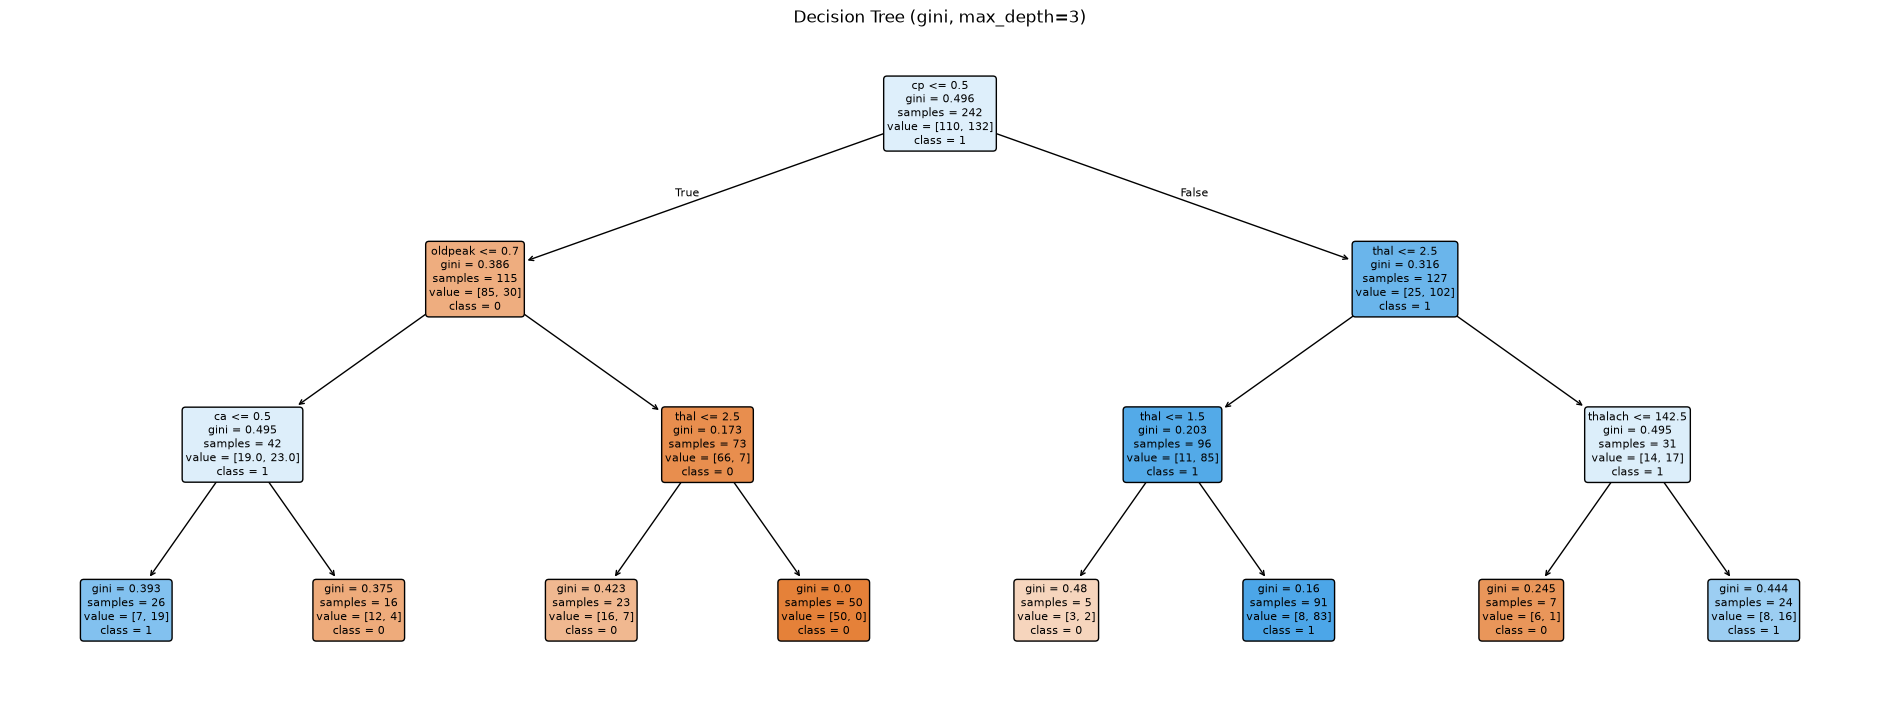

|--- cp <= 0.50
|   |--- oldpeak <= 0.70
|   |   |--- ca <= 0.50
|   |   |   |--- weights: [7.00, 19.00] class: 1
|   |   |--- ca >  0.50
|   |   |   |--- weights: [12.00, 4.00] class: 0
|   |--- oldpeak >  0.70
|   |   |--- thal <= 2.50
|   |   |   |--- weights: [16.00, 7.00] class: 0
|   |   |--- thal >  2.50
|   |   |   |--- weights: [50.00, 0.00] class: 0
|--- cp >  0.50
|   |--- thal <= 2.50
|   |   |--- thal <= 1.50
|   |   |   |--- weights: [3.00, 2.00] class: 0
|   |   |--- thal >  1.50
|   |   |   |--- weights: [8.00, 83.00] class: 1
|   |--- thal >  2.50
|   |   |--- thalach <= 142.50
|   |   |   |--- weights: [6.00, 1.00] class: 0
|   |   |--- thalach >  142.50
|   |   |   |--- weights: [8.00, 16.00] class: 1



In [5]:
tree = make_pipe(DecisionTreeClassifier(criterion=CRITERION, max_depth=MAX_DEPTH, min_samples_leaf=MIN_LEAF, random_state=SEED), X_train, scale=None)
tree.fit(X_train, y_train)
fn = list(tree.named_steps["prep"].get_feature_names_out())
dt = tree.named_steps["model"]
cls_names = [str(c) for c in dt.classes_]
print(f"ความลึก = {dt.get_depth()} · จำนวนใบ = {dt.get_n_leaves()}")
print(f"train accuracy = {accuracy_score(y_train, tree.predict(X_train)):.4f} · test accuracy = {accuracy_score(y_test, tree.predict(X_test)):.4f}")
plt.figure(figsize=(min(24, 4 + 3 * 2 ** min(dt.get_depth(), 4)), 2.2 * dt.get_depth() + 2))
plot_tree(dt, feature_names=fn, class_names=cls_names, filled=True, rounded=True, fontsize=8, impurity=True, proportion=False)
plt.title(f"Decision Tree ({CRITERION}, max_depth={MAX_DEPTH})"); plt.show()
print(export_text(dt, feature_names=fn, show_weights=True))

In [6]:
# กฎ IF-THEN จากทุกใบ (path จาก root → leaf)
from sklearn.tree import _tree
def tree_rules(dt, fn):
    t = dt.tree_; rules = []
    def walk(node, conds):
        if t.feature[node] == _tree.TREE_UNDEFINED:
            v = t.value[node][0]; k = int(np.argmax(v))
            rules.append({"rule": "IF " + (" AND ".join(conds) or "TRUE") + f" THEN {dt.classes_[k]}",
                          "samples": int(t.n_node_samples[node]), "confidence": float(v[k] / v.sum())})
            return
        f, th = fn[t.feature[node]], t.threshold[node]
        walk(t.children_left[node], conds + [f"{f} <= {th:.3f}"]); walk(t.children_right[node], conds + [f"{f} > {th:.3f}"])
    walk(0, []); return pd.DataFrame(rules).sort_values("samples", ascending=False)
with pd.option_context("display.max_colwidth", 200):
    display(tree_rules(dt, fn))
fi = pd.Series(dt.feature_importances_, index=fn).sort_values(ascending=False)
display(fi[fi > 0].to_frame("importance"))
print(f"✍️ root node = {fn[dt.tree_.feature[0]]} (threshold {dt.tree_.threshold[0]:.3f}) · feature สำคัญสุด: {', '.join(fi.index[:3])}")

,rule,samples,confidence
5,IF cp > 0.500 AND thal <= 2.500 AND thal > 1.500 THEN 1,91,0.9121
3,IF cp <= 0.500 AND oldpeak > 0.700 AND thal > 2.500 THEN 0,50,1.0000
0,IF cp <= 0.500 AND oldpeak <= 0.700 AND ca <= 0.500 THEN 1,26,0.7308
7,IF cp > 0.500 AND thal > 2.500 AND thalach > 142.500 THEN 1,24,0.6667
2,IF cp <= 0.500 AND oldpeak > 0.700 AND thal <= 2.500 THEN 0,23,0.6957
1,IF cp <= 0.500 AND oldpeak <= 0.700 AND ca > 0.500 THEN 0,16,0.7500
6,IF cp > 0.500 AND thal > 2.500 AND thalach <= 142.500 THEN 0,7,0.8571
4,IF cp > 0.500 AND thal <= 2.500 AND thal <= 1.500 THEN 0,5,0.6000


,importance
cp,0.5490
oldpeak,0.1683
thal,0.1659
ca,0.0708
thalach,0.0460


✍️ root node = cp (threshold 0.500) · feature สำคัญสุด: cp, oldpeak, thal


**✍️ คำตอบ §2:** root = … · กฎหลัก: IF … AND … THEN … (… ตัวอย่าง, confidence …) · feature สำคัญสุด …

## §3 Overfitting — train vs CV accuracy ตาม max_depth
ต้นไม้ลึก → train ~100% แต่ CV ต่ำ = **overfit** (จำ noise) · แก้: จำกัด max_depth, เพิ่ม min_samples_leaf, pruning (ccp_alpha), ใช้ RF

,max_depth,train_acc,cv_acc,cv_f1,gap
0,1,0.7607,0.7292,0.7505,0.0315
1,2,0.7830,0.7460,0.7815,0.0370
2,3,0.8515,0.8052,0.8259,0.0463
3,4,0.8927,0.7654,0.7920,0.1274
4,5,0.9365,0.7357,0.7608,0.2008
5,6,0.9637,0.7489,0.7759,0.2149
6,7,0.9827,0.7455,0.7680,0.2372
7,8,0.9926,0.7223,0.7455,0.2703
8,9,0.9967,0.7455,0.7705,0.2512
9,10,0.9992,0.7322,0.7592,0.2670


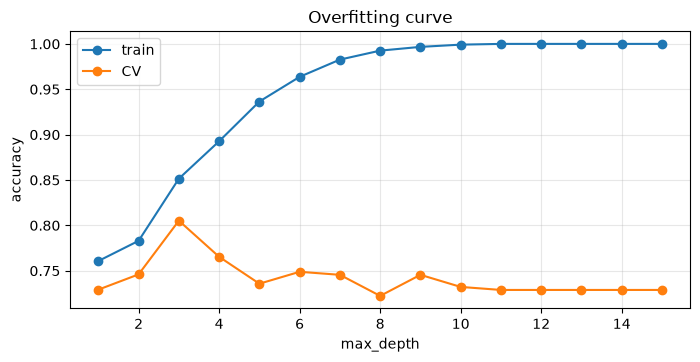

✍️ ต้นไม้เต็ม: train 1.0000 vs CV 0.7289 (gap 0.2711) → overfit · ความลึกที่ดีสุด = 3 (CV acc 0.8052)


In [7]:
depths = list(range(1, 16))
dc = []
for d in depths:
    r = cross_validate(make_pipe(DecisionTreeClassifier(criterion=CRITERION, max_depth=d, random_state=SEED), X, scale=None),
                       X, y, cv=cv, scoring=cls_scoring(y), return_train_score=True)
    dc.append({"max_depth": d, "train_acc": r["train_accuracy"].mean(), "cv_acc": r["test_accuracy"].mean(), "cv_f1": r["test_f1"].mean()})
r = cross_validate(make_pipe(DecisionTreeClassifier(criterion=CRITERION, random_state=SEED), X, scale=None), X, y, cv=cv, scoring=cls_scoring(y), return_train_score=True)
dc.append({"max_depth": "None (full)", "train_acc": r["train_accuracy"].mean(), "cv_acc": r["test_accuracy"].mean(), "cv_f1": r["test_f1"].mean()})
dc = pd.DataFrame(dc); dc["gap"] = dc.train_acc - dc.cv_acc
display(dc.round(4))
plt.figure(figsize=(8, 3.6)); plt.plot(depths, dc.train_acc[:-1], "o-", label="train"); plt.plot(depths, dc.cv_acc[:-1], "o-", label="CV")
plt.xlabel("max_depth"); plt.ylabel("accuracy"); plt.title("Overfitting curve"); plt.legend(); plt.show()
bd = dc.iloc[:-1].loc[dc.iloc[:-1].cv_acc.idxmax()]
full = dc.iloc[-1]
print(f"✍️ ต้นไม้เต็ม: train {full.train_acc:.4f} vs CV {full.cv_acc:.4f} (gap {full.gap:.4f}) → overfit · ความลึกที่ดีสุด = {bd.max_depth} (CV acc {bd.cv_acc:.4f})")

## §4 Tune Decision Tree (GridSearchCV: max_depth × min_samples_leaf × criterion)

In [8]:
g_dt = GridSearchCV(make_pipe(DecisionTreeClassifier(random_state=SEED), X, scale=None),
                    {"model__max_depth": [2, 3, 4, 5, 6, 8, 10, None], "model__min_samples_leaf": [1, 2, 5, 10, 20],
                     "model__criterion": ["gini", "entropy"]}, cv=cv, scoring=cls_scoring(y), refit="f1").fit(X, y)
print("best:", g_dt.best_params_, "| CV F1 =", round(g_dt.best_score_, 4)); display(top_k(g_dt, 8))

best: {'model__criterion': 'entropy', 'model__max_depth': 3, 'model__min_samples_leaf': 5} | CV F1 = 0.8374


,param_model__criterion,param_model__max_depth,param_model__min_samples_leaf,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1
0,entropy,3,5,0.8152,0.8121,0.8667,0.8374
1,entropy,10,10,0.8084,0.7805,0.9030,0.8369
2,entropy,4,10,0.8084,0.7805,0.9030,0.8369
3,entropy,5,10,0.8084,0.7805,0.9030,0.8369
4,entropy,6,10,0.8084,0.7805,0.9030,0.8369
5,entropy,None,10,0.8084,0.7805,0.9030,0.8369
6,entropy,8,10,0.8084,0.7805,0.9030,0.8369
7,entropy,3,10,0.8119,0.8107,0.8606,0.8340


## §5 Random Forest (bagging หลายต้น + สุ่ม feature ทุก split → variance ต่ำกว่า, overfit น้อยกว่า)
พารามิเตอร์: `n_estimators` (จำนวนต้น) · `max_features` (feature ที่สุ่มต่อ split: "sqrt") · `max_depth` · `min_samples_leaf`

RF best: {'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 3, 'model__n_estimators': 100} | CV F1 = 0.8625


,param_model__max_depth,param_model__max_features,param_model__min_samples_leaf,param_model__n_estimators,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1
0,5,sqrt,3,100,0.8416,0.8270,0.9030,0.8625
1,5,sqrt,5,300,0.8283,0.8161,0.8909,0.8509
2,5,sqrt,1,300,0.8284,0.8159,0.8909,0.8509
3,5,sqrt,5,100,0.8283,0.8210,0.8848,0.8503
4,5,sqrt,3,300,0.8284,0.8192,0.8848,0.8500


,0,1,2,3,4,5,6,7
n_estimators,1.0000,5.0000,10.0000,25.0000,50.0000,100.0000,200.0000,400.0000
cv_acc,0.7627,0.8186,0.8284,0.8085,0.8217,0.8152,0.8185,0.8218


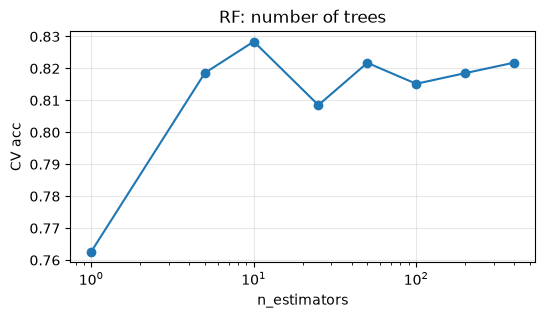

In [9]:
rf = make_pipe(RandomForestClassifier(n_estimators=N_TREES, random_state=SEED), X, scale=None)
g_rf = GridSearchCV(make_pipe(RandomForestClassifier(random_state=SEED), X, scale=None),
                    {"model__n_estimators": [100, 300], "model__max_depth": [None, 5, 10],
                     "model__min_samples_leaf": [1, 3, 5], "model__max_features": ["sqrt", None]},
                    cv=cv, scoring=cls_scoring(y), refit="f1", n_jobs=-1).fit(X, y)
print("RF best:", g_rf.best_params_, "| CV F1 =", round(g_rf.best_score_, 4)); display(top_k(g_rf, 5))
# ผลของจำนวนต้น
nt = []
for n in [1, 5, 10, 25, 50, 100, 200, 400]:
    r = cross_validate(make_pipe(RandomForestClassifier(n_estimators=n, random_state=SEED), X, scale=None), X, y, cv=cv, scoring="accuracy")
    nt.append({"n_estimators": n, "cv_acc": r["test_score"].mean()})
nt = pd.DataFrame(nt); display(nt.T.round(4))
plt.figure(figsize=(6, 3)); plt.plot(nt.n_estimators, nt.cv_acc, "o-"); plt.xscale("log"); plt.xlabel("n_estimators"); plt.ylabel("CV acc"); plt.title("RF: number of trees"); plt.show()

## §6 เปรียบเทียบ baseline vs DT vs RF (ก่อน/หลัง optimize) ⭐

,model,settings,accuracy,precision,recall,f1,f1_std,train_accuracy
0,Majority baseline,,0.5446,0.5446,1.0000,0.7051,0.0037,0.5446
1,Decision Tree (full),no limit,0.7289,0.7482,0.7636,0.7553,0.0531,1.0000
2,Decision Tree (depth=3),โจทย์กำหนด,0.8052,0.8135,0.8424,0.8259,0.0366,0.8515
3,Decision Tree tuned,"{'model__criterion': 'entropy', 'model__max_de...",0.8152,0.8121,0.8667,0.8374,0.0347,0.8474
4,Random Forest (100),default,0.8152,0.8132,0.8667,0.8371,0.0225,1.0000
5,Random Forest tuned,"{'model__max_depth': 5, 'model__max_features':...",0.8416,0.8270,0.9030,0.8625,0.0480,0.9216


✍️ โมเดลที่ดีที่สุดตาม f1 คือ Random Forest tuned ({'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 3, 'model__n_estimators': 100}) ได้ f1 = 0.8625 เทียบกับ baseline (Majority baseline) ที่ได้ 0.7051 ต่างกัน +0.1573 (baseline accuracy = 0.5446 แต่ f1 ต่ำ → accuracy อย่างเดียวหลอกได้ถ้าคลาสไม่สมดุล)


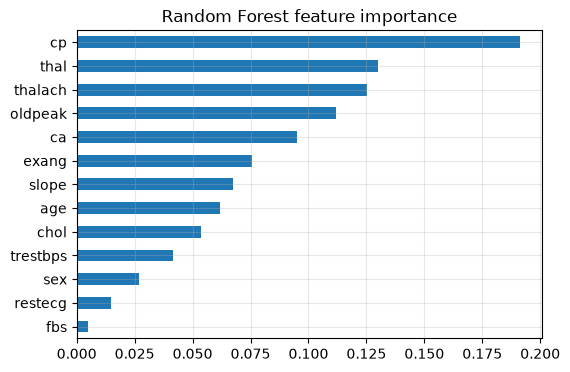

RF tuned บน test:


,pred 0,pred 1
actual 0,19,9
actual 1,1,32


TN=19  FP=9  FN=1  TP=32
              precision    recall  f1-score   support

           0     0.9500    0.6786    0.7917        28
           1     0.7805    0.9697    0.8649        33

    accuracy                         0.8361        61
   macro avg     0.8652    0.8241    0.8283        61
weighted avg     0.8583    0.8361    0.8313        61



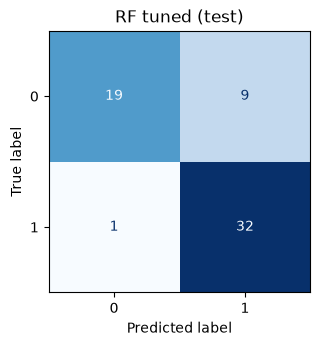

In [10]:
rows = [evaluate("Majority baseline", DummyClassifier(strategy="most_frequent"), X, y, cv, train=True),
        evaluate("Decision Tree (full)", make_pipe(DecisionTreeClassifier(criterion=CRITERION, random_state=SEED), X, scale=None), X, y, cv, "no limit", train=True),
        evaluate(f"Decision Tree (depth={MAX_DEPTH})", make_pipe(DecisionTreeClassifier(criterion=CRITERION, max_depth=MAX_DEPTH, min_samples_leaf=MIN_LEAF, random_state=SEED), X, scale=None), X, y, cv, "โจทย์กำหนด", train=True),
        evaluate("Decision Tree tuned", g_dt.best_estimator_, X, y, cv, str(g_dt.best_params_), train=True),
        evaluate(f"Random Forest ({N_TREES})", rf, X, y, cv, "default", train=True),
        evaluate("Random Forest tuned", g_rf.best_estimator_, X, y, cv, str(g_rf.best_params_), train=True)]
cmp_t = results_table(rows)
say_compare(cmp_t, "f1", "Majority baseline")
best_rf = g_rf.best_estimator_.fit(X_train, y_train)
fi_rf = pd.Series(best_rf.named_steps["model"].feature_importances_, index=best_rf.named_steps["prep"].get_feature_names_out()).sort_values(ascending=False)
fi_rf.head(15).plot(kind="barh", figsize=(6, 4), title="Random Forest feature importance"); plt.gca().invert_yaxis(); plt.show()
print("RF tuned บน test:"); show_cm(y_test, best_rf.predict(X_test), "RF tuned (test)")

**✍️ คำตอบ §6:** ต้นไม้เต็ม train … CV … → overfit · จำกัด depth = … ได้ CV F1 … · RF ได้ … ดีกว่า/ใกล้ DT เพราะเฉลี่ยหลายต้นลด variance · feature สำคัญ (RF) = …

## §7 ทำนายข้อมูลใหม่ + อธิบายเส้นทางในต้นไม้

In [11]:
nd = align_new(new_data(NEW_DATA), X) if NEW_DATA is not None else X_test.iloc[[0]]
out = nd.copy()
out["DT pred"] = tree.predict(nd); out["DT P(1)"] = tree.predict_proba(nd)[:, -1]
out["RF pred"] = best_rf.predict(nd); out["RF P(1)"] = best_rf.predict_proba(nd)[:, -1]
display(out)
xr = tree.named_steps["prep"].transform(nd.iloc[[0]])
path = dt.decision_path(xr).indices
steps = []
for node in path:
    if dt.tree_.children_left[node] == -1:
        v = dt.tree_.value[node][0]; steps.append(f"→ leaf: class {dt.classes_[np.argmax(v)]} ({v.max() / v.sum():.1%})")
    else:
        f, th = dt.tree_.feature[node], dt.tree_.threshold[node]
        steps.append(f"{fn[f]} = {xr[0, f]:g} {'<=' if xr[0, f] <= th else '>'} {th:.3f}")
print("✍️ เส้นทาง:", " | ".join(steps))

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,DT pred,DT P(1),RF pred,RF P(1)
179,57,1,0,150,276,0,0,112,1,0.6000,1,1,1,0,0.2500,0,0.1997


✍️ เส้นทาง: cp = 0 <= 0.500 | oldpeak = 0.6 <= 0.700 | ca = 1 > 0.500 | → leaf: class 0 (75.0%)
